# Task 1. Adding Problem

The objective of this notebook is running the adding problem comparision and understanding the results

## 1. Preparación del entorno

Esta primera etapa comprueba que Colab tiene las bibliotecas necesarias. No entrenaremos ningún modelo todavía.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"Dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

Python: 3.13.16
NumPy: 2.1.3
PyTorch: 2.11.0+cu130
Dispositivo: cuda


## 2. Ejecutar el experimento desde la terminal de Colab

El artículo evalúa el problema con `T=200`, `T=400` y `T=600`. El script `add_test.py` implementa el experimento del TCN. En esta etapa clonamos el repositorio y ejecutamos primero el caso `T=200`.

In [2]:
!if [ ! -d /content/TCN/.git ]; then git clone https://github.com/botellopai18/TCN.git /content/TCN; fi
%cd /content/TCN/TCN/adding_problem
!python add_test.py -h

/content/TCN/TCN/adding_problem
usage: add_test.py [-h] [--batch_size N] [--cuda] [--dropout DROPOUT]
                   [--clip CLIP] [--epochs EPOCHS] [--ksize KSIZE]
                   [--levels LEVELS] [--seq_len SEQ_LEN] [--log-interval N]
                   [--lr LR] [--optim OPTIM] [--nhid NHID] [--seed SEED]

Sequence Modeling - The Adding Problem

options:
  -h, --help         show this help message and exit
  --batch_size N     batch size (default: 32)
  --cuda             use CUDA (default: True)
  --dropout DROPOUT  dropout applied to layers (default: 0.0)
  --clip CLIP        gradient clip, -1 means no clip (default: -1)
  --epochs EPOCHS    upper epoch limit (default: 10)
  --ksize KSIZE      kernel size (default: 7)
  --levels LEVELS    # of levels (default: 8)
  --seq_len SEQ_LEN  sequence length (default: 400)
  --log-interval N   report interval (default: 100
  --lr LR            initial learning rate (default: 4e-3)
  --optim OPTIM      optimizer to use (default: Ada

### 2.1. Primera prueba: `T=200`

Para este caso usamos los hiperparámetros del artículo: `kernel_size=6`, `levels=7` y `hidden=27`. No agregamos `--cuda`, porque en este script CUDA está activado por defecto; esa bandera lo desactiva.

In [3]:
!python add_test.py --seq_len 200 --ksize 6 --levels 7 --nhid 27 --dropout 0.0 --epochs 10 --log-interval 100 2>&1 | tee results_T200.txt

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=10, ksize=6, levels=7, seq_len=200, log_interval=100, lr=0.004, optim='Adam', nhid=27, seed=1111)
Producing data...
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.242527
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.176476
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.169249
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.166098
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.167718
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.161332
Train Epoch:  1 [ 22368/ 50000 (45%)]	Learning rate: 0.0040	Loss: 0.169524
Train Epoch:  1 [ 25568/ 50000 (51%)]	Learning rate: 0.0040	Loss:

Tests bitacora:
- 10 epochs, 100 log_interval: 2min
- 20 epochs, 10 log_interval: 4min


### 2.2. Comprobar el tamaño de los modelos

El artículo mantiene los modelos cerca de 70,000 parámetros. Esta celda calcula el tamaño de cada configuración TCN antes de ejecutar las otras pruebas.

In [4]:
sys.path.insert(0, '/content/TCN')

from TCN.adding_problem.model import TCN

configs = {
    200: {'ksize': 6, 'levels': 7, 'nhid': 27},
    400: {'ksize': 7, 'levels': 7, 'nhid': 27},
    600: {'ksize': 8, 'levels': 8, 'nhid': 24},
}

for sequence_length, config in configs.items():
    model = TCN(2, 1, [config['nhid']] * config['levels'],
                kernel_size=config['ksize'], dropout=0.0)
    n_parameters = sum(p.numel() for p in model.parameters())
    print(f"T={sequence_length}: {n_parameters:,} parámetros")

T=200: 58,051 parámetros
T=400: 67,582 parámetros
T=600: 70,369 parámetros


/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


### 2.3. Pruebas `T=400` y `T=600`

Estas dos celdas ejecutan las otras longitudes usadas en el artículo. Cada salida se guarda en un archivo de texto para poder graficar la convergencia después.

In [5]:
!python add_test.py --seq_len 400 --ksize 7 --levels 7 --nhid 27 --dropout 0.0 --epochs 10 --log-interval 100 2>&1 | tee results_T400.txt

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=10, ksize=7, levels=7, seq_len=400, log_interval=100, lr=0.004, optim='Adam', nhid=27, seed=1111)
Producing data...
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.228625
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.174631
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.167275
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.166333
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.167938
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.166911
Train Epoch:  1 [ 22368/ 50000 (45%)]	Learning rate: 0.0040	Loss: 0.170542
Train Epoch:  1 [ 25568/ 50000 (51%)]	Learning rate: 0.0040	Loss:

Bitacora tests:
- 10 epochs, log_interval=100: 2 min
- 20 epochs, log_interval=10: 4min

In [6]:
!python add_test.py --seq_len 600 --ksize 8 --levels 8 --nhid 24 --dropout 0.0 --epochs 10 --log-interval 100 2>&1 | tee results_T600.txt

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=10, ksize=8, levels=8, seq_len=600, log_interval=100, lr=0.004, optim='Adam', nhid=24, seed=1111)
Producing data...
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.456931
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.168483
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.169628
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.177005
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.178850
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.168702
Train Epoch:  1 [ 22368/ 50000 (45%)]	Learning rate: 0.0040	Loss: 0.165066
Train Epoch:  1 [ 25568/ 50000 (51%)]	Learning rate: 0.0040	Loss:

Bitacora resultados:
- 10 epochs, 100 lg_interval: 3 min
- 20 epochs, 10 log_interval: 6min

## 3. Analizar la convergencia

`add_test.py` imprime la pérdida de entrenamiento cada cierto número de lotes y la pérdida de prueba al final de cada época. La siguiente celda lee los tres logs y grafica la evolución del error.

T=200: 10 épocas; última iteración=15630
T=400: 10 épocas; última iteración=15630
T=600: 10 épocas; última iteración=15630


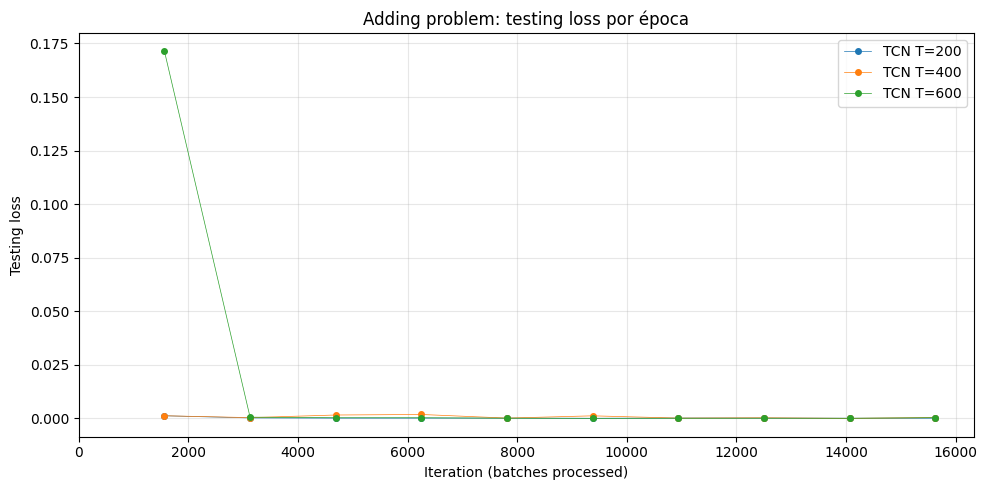

In [7]:
import re
from pathlib import Path

def read_test_losses(path):
    text = Path(path).read_text()
    return [float(value) for value in re.findall(r'Average loss: ([0-9.eE+-]+)', text)]

batch_size = 32
n_train = 50_000
steps_per_epoch = int(np.ceil(n_train / batch_size))
test_results = {}

for sequence_length in (200, 400, 600):
    test_losses = read_test_losses(f'results_T{sequence_length}.txt')
    epochs = np.arange(1, len(test_losses) + 1)
    iterations = epochs * steps_per_epoch
    test_results[sequence_length] = (iterations, test_losses)
    print(f"T={sequence_length}: {len(test_losses)} épocas; última iteración={iterations[-1]}")

fig, ax = plt.subplots(figsize=(10, 5))
for sequence_length, (iterations, test_losses) in test_results.items():
    ax.plot(iterations, test_losses, linewidth=0.5, marker='o', markersize=4,
            label=f'TCN T={sequence_length}')
ax.set_xlabel('Iteration (batches processed)')
ax.set_ylabel('Testing loss')
ax.set_title('Adding problem: testing loss por época')
ax.set_xlim(left=0)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## 4. Alcance de esta réplica

El repositorio disponible contiene el experimento TCN en `add_test.py`; no contiene implementaciones de los baselines RNN, LSTM y GRU usados en la comparación del artículo. Por eso este notebook reproduce primero las tres curvas TCN (`T=200`, `T=400` y `T=600`). Para igualar completamente la figura del artículo habrá que añadir esos tres modelos con un número comparable de parámetros y registrar sus pérdidas con el mismo protocolo.